# SmartSpace AI - Jupyter ML Workflow

This notebook workflow trains a rental price prediction model without using an API. It analyzes uploaded datasets, cleans data, compares three ML models using cross-validation, selects the best model, saves `model.pkl`, and generates Explainable AI output.

In [1]:
from pathlib import Path
import sys

PROJECT_ML_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(PROJECT_ML_DIR))
PROJECT_ML_DIR

WindowsPath('C:/Users/vinod/Documents/Codex/2026-07-14/you-are-a-senior-staff-software-2/ml')

## 1. Load Dataset Helpers

In [2]:
from preprocessing import DEFAULT_DATASETS, analyze_datasets, load_price_training_frame
from streamlit_train import train_and_select_best, REPORT_DIR, MODEL_DIR

DEFAULT_DATASETS

['C:\\Users\\vinod\\Downloads\\RS_Session_260_AU_1168_A_to_C.csv',
 'C:\\Users\\vinod\\Downloads\\Table_7_10.csv',
 'C:\\Users\\vinod\\Downloads\\export.geojson',
 'C:\\Users\\vinod\\Downloads\\house_prices_bangalore.csv',
 'C:\\Users\\vinod\\Downloads\\Fleet_Nov_2021.csv',
 'C:\\Users\\vinod\\Downloads\\Fleet_Jan_2022_0.csv',
 'C:\\Users\\vinod\\Downloads\\Fleet_Dec_2021_0.csv',
 'C:\\Users\\vinod\\Downloads\\bengaluru_house_prices (1).csv',
 'C:\\Users\\vinod\\Downloads\\5c2f62fe-5afa-4119-a499-fec9d604d5bd.csv',
 'C:\\Users\\vinod\\Downloads\\Airbnb_Data.csv.zip',
 'C:\\Users\\vinod\\Downloads\\bengaluru_house_prices.csv',
 'C:\\Users\\vinod\\Downloads\\data.csv',
 'C:\\Users\\vinod\\Downloads\\Indian_Real_Estate_Clean_Data.csv.zip',
 'C:\\Users\\vinod\\Downloads\\Real Estate Data V21.csv.zip']

## 2. EDA: Structure, Missing Values, Duplicates

In [3]:
eda = analyze_datasets(DEFAULT_DATASETS)
eda

{'RS_Session_260_AU_1168_A_to_C.csv': {'rows': 27,
  'columns': ['Sl. No.',
   'Title',
   'Sector',
   'Milestone',
   'Project Cost (In Rs. Crore)',
   'Progress in %',
   'source_file'],
  'missing': {'Sl. No.': 0,
   'Title': 0,
   'Sector': 0,
   'Milestone': 0,
   'Project Cost (In Rs. Crore)': 0,
   'Progress in %': 0,
   'source_file': 0},
  'duplicates': 0,
  'numeric_columns': ['Project Cost (In Rs. Crore)', 'Progress in %'],
  'categorical_columns': ['Sl. No.',
   'Title',
   'Sector',
   'Milestone',
   'source_file']},
 'Table_7_10.csv': {'rows': 8,
  'columns': ['States',
   'Total No. of Sample Beneficiaries',
   'Bus Stand: Before Rural Road - Yes',
   'Bus Stand: Before Rural Road - No',
   'Bus Stand: Before Rural Road - NA',
   'Bus Stand: After Rural Road - IS',
   'Bus Stand: After Rural Road - IM',
   'Bus Stand: After Rural Road - NC',
   'Bus Stand: After Rural Road - DET',
   'Bus Stand: Magnitude of Response in Percentage - IS',
   'Bus Stand: Magnitude of Res

## 3. Clean and Feature Engineer Data

In [4]:
df = load_price_training_frame(DEFAULT_DATASETS)
print(df.shape)
df.head()

(133346, 16)


,source_file,city,locality,property_type,furnishing,amenities,description,area,beds,bathrooms,balconies,target_price,target_type,log_area,amenity_count,description_length
0,house_prices_bangalore.csv,bangalore,bannerghatta road,independent house,semi-furnished,,,2065.0,2.0,3.0,0.0,17280000.0,sale_price,7.633370,1,0
1,house_prices_bangalore.csv,bangalore,yelahanka,villa,unfurnished,,,1539.0,3.0,1.0,0.0,9410000.0,sale_price,7.339538,1,0
2,house_prices_bangalore.csv,bangalore,bannerghatta road,independent house,semi-furnished,,,2048.0,3.0,1.0,2.0,20300000.0,sale_price,7.625107,1,0
3,house_prices_bangalore.csv,bangalore,sarjapur road,apartment,fully-furnished,,,1233.0,3.0,2.0,1.0,9060000.0,sale_price,7.118016,1,0
4,house_prices_bangalore.csv,bangalore,yelahanka,villa,fully-furnished,,,2487.0,3.0,3.0,2.0,28660000.0,sale_price,7.819234,1,0


## 4. Train Three Models with Cross-Validation

Models:
- Ridge Regression
- Random Forest
- Gradient Boosting

In [5]:
report = train_and_select_best()
report['best_model'], report['models']

('Gradient Boosting',
 {'Ridge Regression': {'cv_mae': 1254932.5494984712,
   'cv_rmse': 3091242.4688400617,
   'cv_r2': 0.4622031735637984,
   'train_cv_rmse': 3089738.832317771,
   'validation': {'mae': 1245668.763054632,
    'rmse': 3066503.0848211255,
    'r2': 0.45988080951843513},
   'test': {'mae': 1273668.7184103453,
    'rmse': 3144651.05245063,
    'r2': 0.4595638906605949},
   'overfit_gap_rmse': 1503.6365222907625},
  'Random Forest': {'cv_mae': 868400.8409105534,
   'cv_rmse': 2697267.8346485686,
   'cv_r2': 0.5905463012662404,
   'train_cv_rmse': 2622115.807026089,
   'validation': {'mae': 859836.9196879768,
    'rmse': 2672092.206228102,
    'r2': 0.5898849783367048},
   'test': {'mae': 864556.1932862516,
    'rmse': 2713921.8256562264,
    'r2': 0.5974738452363448},
   'overfit_gap_rmse': 75152.02762247948},
  'Gradient Boosting': {'cv_mae': 871856.6599725155,
   'cv_rmse': 2683417.885820542,
   'cv_r2': 0.5947512253399275,
   'train_cv_rmse': 2655744.8516076254,
   'va

## 5. Explainable AI

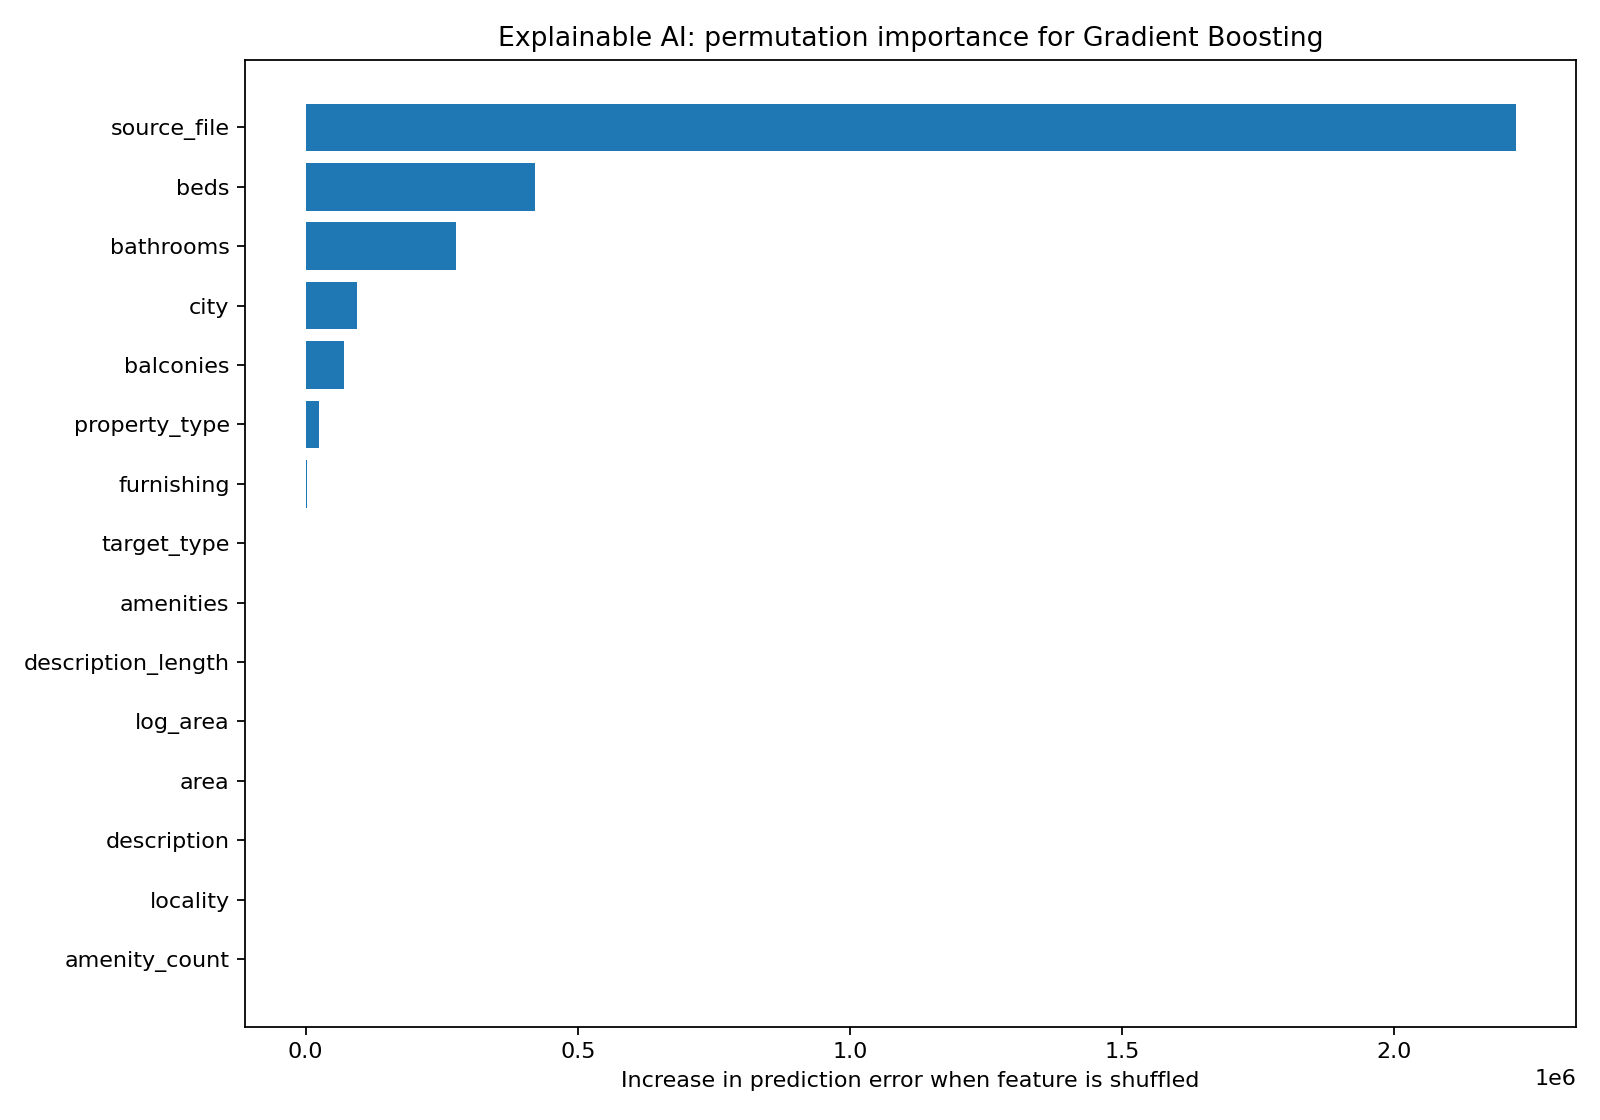

In [6]:
from IPython.display import Image, display
display(Image(filename=str(REPORT_DIR / 'explainable_ai_permutation_importance.png')))

## 6. Saved Artifacts

The workflow saves:
- `models_streamlit/model.pkl`
- `models_streamlit/preprocessing_pipeline.pkl`
- `models_streamlit/training_metadata.pkl`
- `reports_streamlit/training_report.json`
- `reports_streamlit/explainable_ai_permutation_importance.png`